# Link Splendor Scores

We generate plots of the link-level splendor score:
- a map of the main specification (as defined in [src/splendor/config.py](../../src/splendor/config.py))
- close-ups of the highest- and lowest-ranked links
- how sensitive the ranking is to the methodological choices (normalization, aggregation, component weights, land use measure)

To do this, we read the output from [scripts/compute_link_score.py](../../scripts/compute_link_score.py).

<br><br>

## 0. Setup

### 0.1. Imports and Config

In [1]:
import pandas as pd

from splendor.config import (
    STUDY_AREA,
    CORRIDOR_RADIUS,
    ROAD_STRIP_RADIUS,
    MAIN_SPECIFICATION,
    POI_BOUNDS,
    COMPONENT_WEIGHTS,
    REFERENCE_WEIGHTS
)
from splendor.io import load_network, load_raster, load_rank_correlations
from splendor.landuse.corridors import get_link_corridors
from splendor.composite.sensitivity import COMBINATION_COLUMNS
from splendor.paths import (
    network_path,
    basemap05_main_types_path,
    link_landuse_path,
    link_score_grid_path,
    link_rank_summary_path,
    link_rank_correlations_path,
    link_splendor_path,
    link_components_path
)
from splendor.plotting.scores import plot_link_maps, plot_rank_correlations
from splendor.plotting.charts import plot_distributions, plot_against
from splendor.plotting.landuse import plot_link_landuse_grid

PATH_ARGS = (STUDY_AREA, CORRIDOR_RADIUS, ROAD_STRIP_RADIUS)
N_CLOSE_UPS = 8 # Links per top/bottom grid

WEIGHT_COLUMNS = ["land_use_weight", "poi_weight", "attractiveness_weight"]
weight_label = lambda weights: "/".join(f"{w:.2g}" for w in weights) # (0.6, 0.2, 0.2) -> "0.6/0.2/0.2"

### 0.2. Data

In [2]:
_, edges = load_network(network_path(STUDY_AREA))
edges = edges.sort_values("edge_id").reset_index(drop=True)

splendor = pd.read_csv(link_splendor_path(*PATH_ARGS))
grid = pd.read_csv(link_score_grid_path(*PATH_ARGS))
summary = pd.read_csv(link_rank_summary_path(*PATH_ARGS))
correlations = load_rank_correlations(link_rank_correlations_path(*PATH_ARGS), COMBINATION_COLUMNS)
components = pd.read_csv(link_components_path(*PATH_ARGS))
links = edges[["edge_id", "length_m", "poi_diversity"]].merge(splendor, on="edge_id", validate="one_to_one")

# For the close-ups
raster, transform, _ = load_raster(basemap05_main_types_path(STUDY_AREA))
shares = pd.read_csv(link_landuse_path(*PATH_ARGS)).set_index("edge_id")
corridors = get_link_corridors(edges, CORRIDOR_RADIUS)

<br><br>

## 1. Main Specification

Main specification: measure shannon, normalization percentile, aggregation mean, land_use_weight 0.5, poi_weight 0.25, attractiveness_weight 0.25


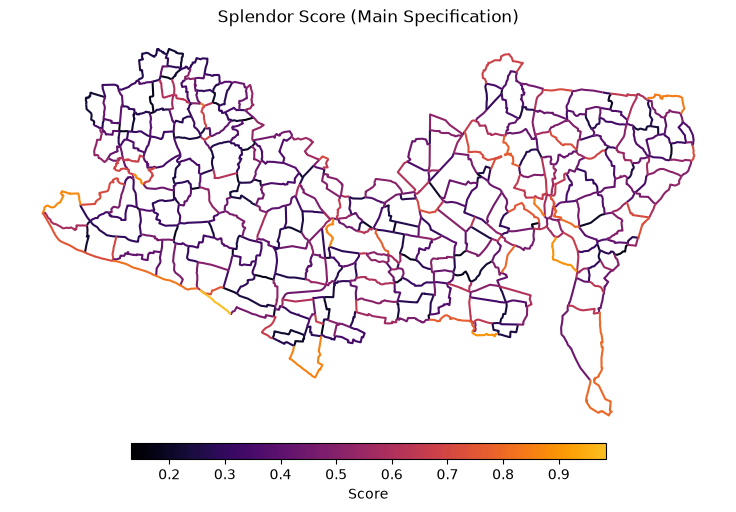

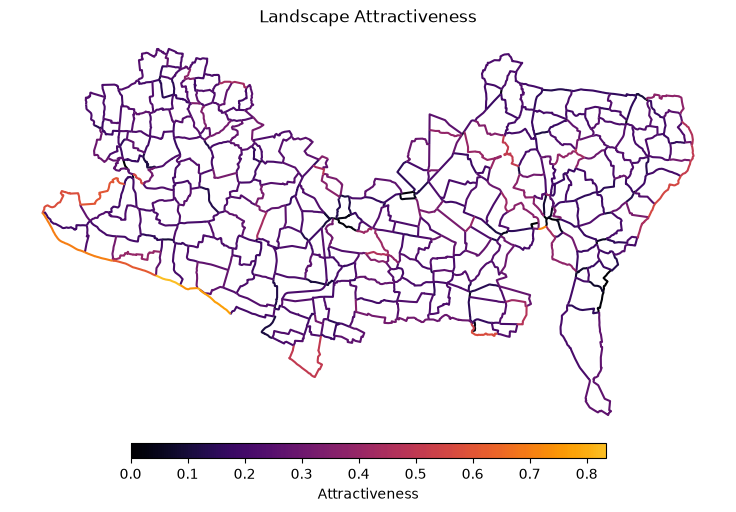

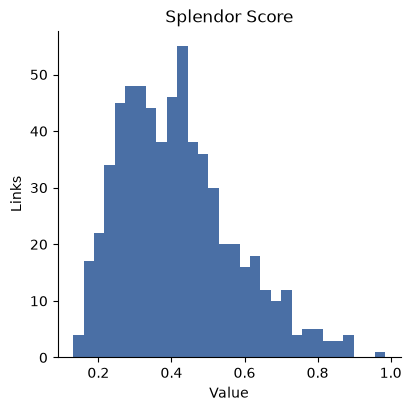

In [3]:
spec = ", ".join(f"{k} {v}" for k, v in MAIN_SPECIFICATION.items())
print("Main specification:", spec)
plot_link_maps(edges, splendor, ["score"], ["Splendor Score (Main Specification)"], ["Score"], panel_size=(8, 5));
plot_link_maps(edges, components, ["attractiveness"], ["Landscape Attractiveness"], ["Attractiveness"], panel_size=(8, 5));
plot_distributions(splendor, ["score"], titles=["Splendor Score"]);

<br><br>

## 2. Top and Bottom links

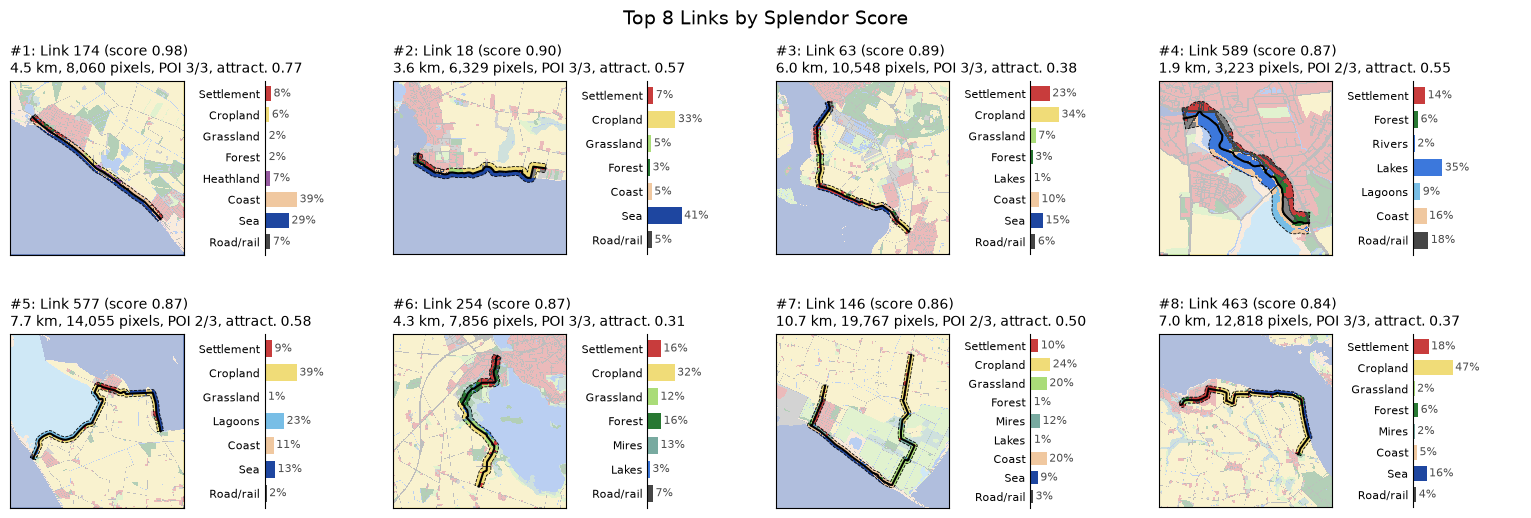

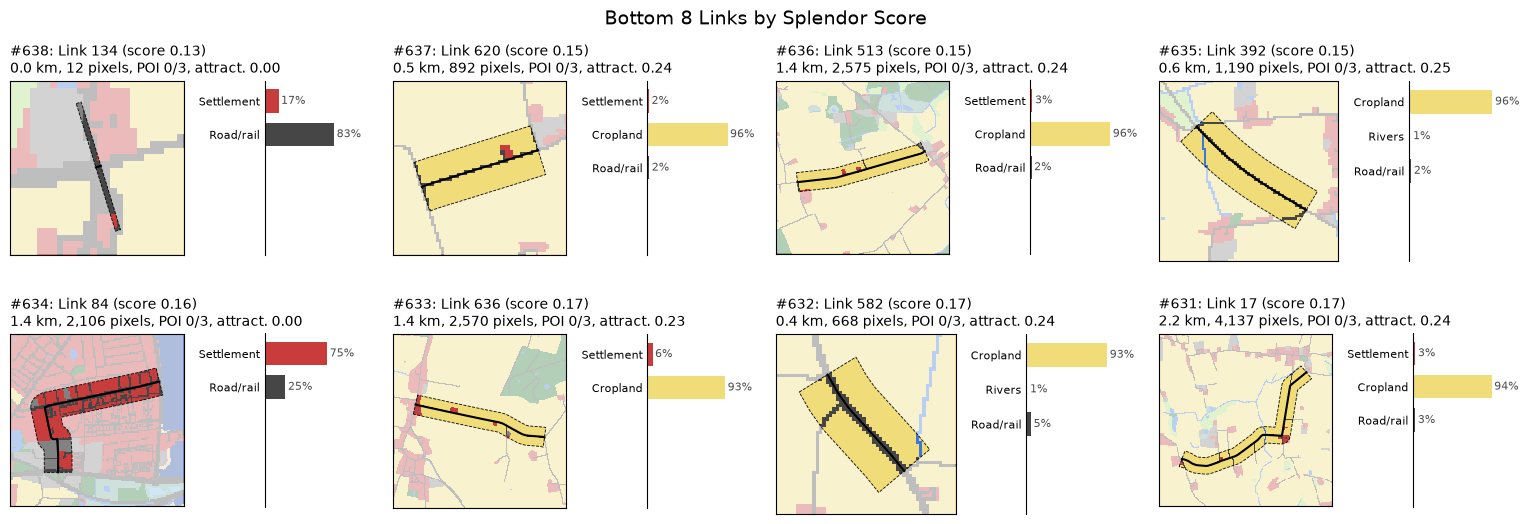

In [4]:
main = splendor.set_index("edge_id")
poi = edges.set_index("edge_id")["poi_diversity"]
attractiveness = components.set_index("edge_id")["attractiveness"]
details = (
    poi.map(lambda p: f"POI {p}/{POI_BOUNDS[1]}")
    + attractiveness.map(lambda a: f", attract. {a:.2f}")
)

top = splendor.nsmallest(N_CLOSE_UPS, "rank")["edge_id"].to_numpy()
bottom = splendor.nlargest(N_CLOSE_UPS, "rank")["edge_id"].to_numpy()

for edge_ids, label in [(top, "Top"), (bottom, "Bottom")]:
    plot_link_landuse_grid(
        edge_ids, edges, corridors, shares, raster, transform,
        ranks=main["rank"], scores=main["score"], details=details,
        title=f"{label} {N_CLOSE_UPS} Links by Splendor Score",
        row_height=2.7,
    )

<br><br>

## 3. Rank Sensitivity

,edge_id,median_rank,iqr_rank,min_rank,max_rank
174,174,1.000000,26.250000,1.000000,117.000000
63,63,3.000000,1.000000,1.000000,5.000000
188,188,4.500000,9.500000,1.000000,19.000000
254,254,4.500000,4.000000,1.000000,12.000000
350,350,5.000000,5.500000,2.000000,12.000000
577,577,5.000000,4.250000,3.000000,14.000000
589,589,6.000000,3.000000,3.000000,14.000000
18,18,6.500000,39.250000,2.000000,118.000000
146,146,7.000000,1.500000,2.000000,16.000000
195,195,9.500000,8.250000,3.000000,23.000000


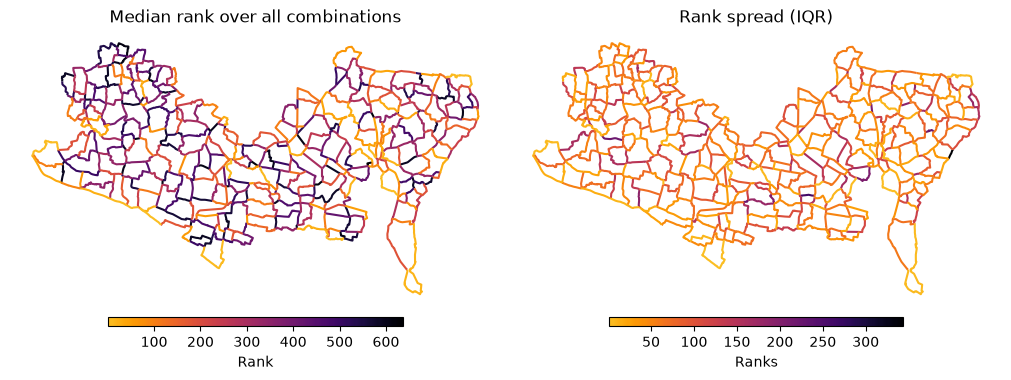

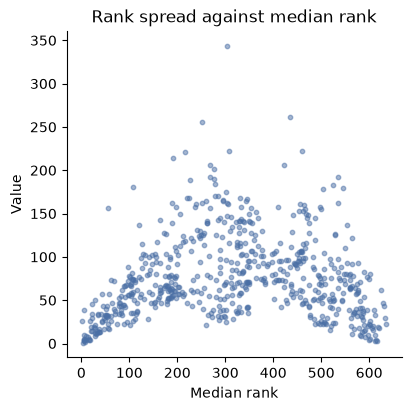

In [5]:
plot_link_maps(
    edges, summary,
    ["median_rank", "iqr_rank"],
    ["Median rank over all combinations", "Rank spread (IQR)"],
    ["Rank", "Ranks"],
    low_is_best=[True, True],
);

plot_against(summary, "median_rank", ["iqr_rank"], titles=["Rank spread against median rank"], xlabel="Median rank");

summary.nsmallest(20, "median_rank")[["edge_id", "median_rank", "iqr_rank", "min_rank", "max_rank"]].style

<br><br>

## 4. Rank Correlations

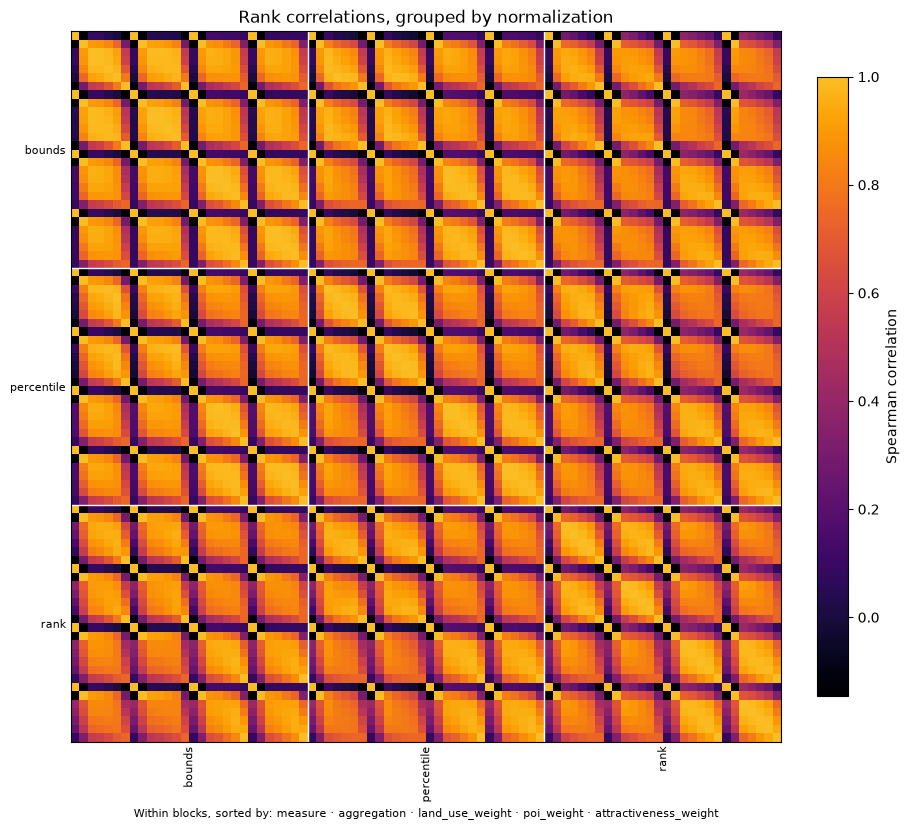

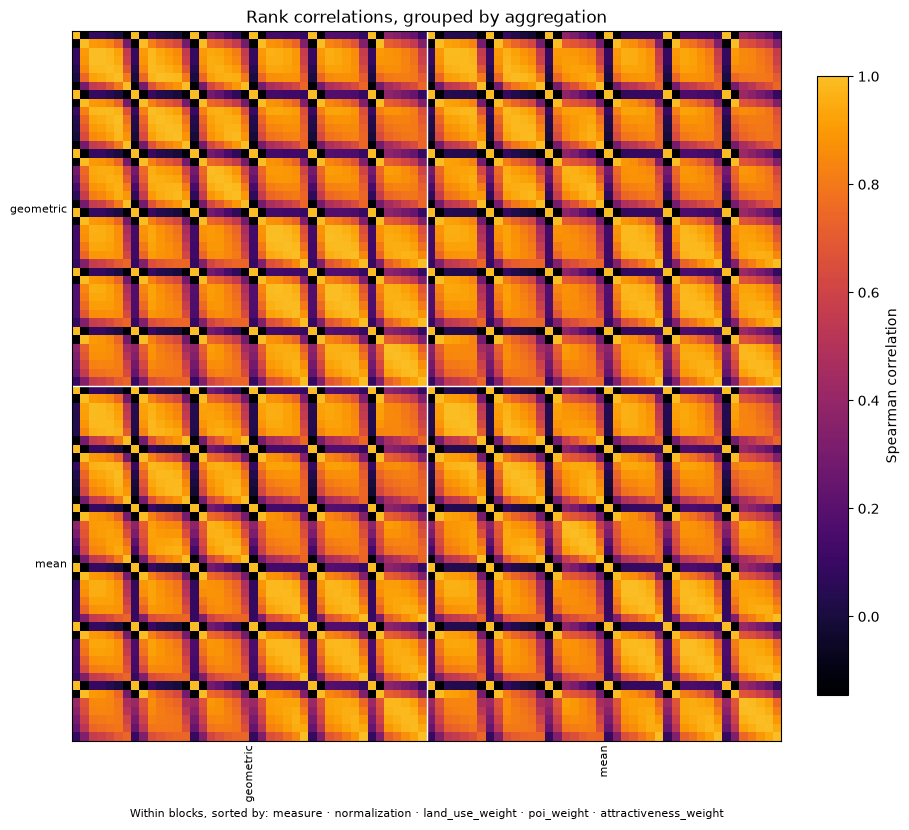

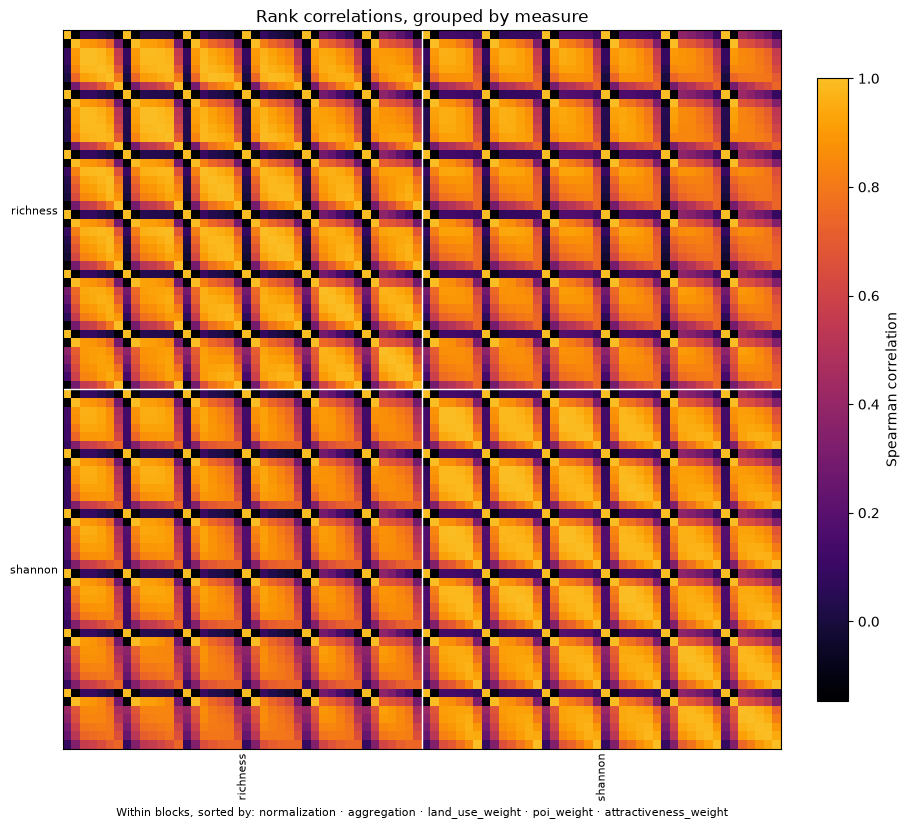

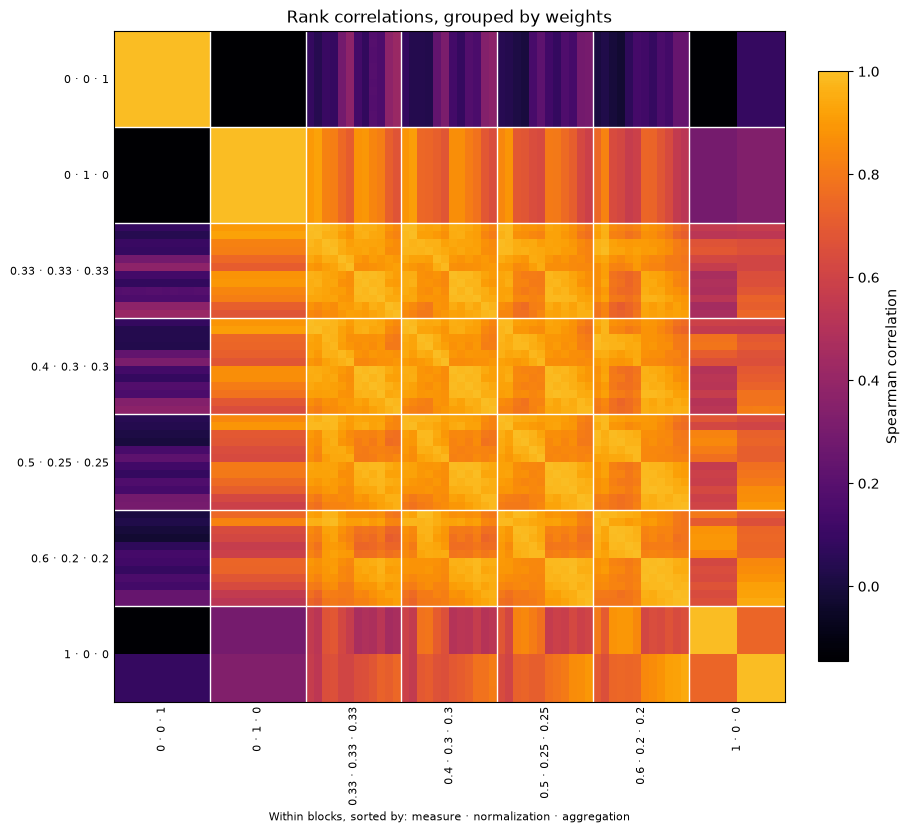

In [6]:
groupings = {
    "normalization": ["normalization"],
    "aggregation": ["aggregation"],
    "measure": ["measure"],
    "weights": ["land_use_weight", "poi_weight", "attractiveness_weight"],
}
for name, outer in groupings.items():
    order = outer + [level for level in COMBINATION_COLUMNS if level not in outer]
    plot_rank_correlations(
        correlations, level_order=order, n_label_levels=len(outer),
        title=f"Rank correlations, grouped by {name}",
    )

<br><br>

## 5. Reference Rankings

weights         0.5/0.25/0.25  0.6/0.2/0.2  0.4/0.3/0.3  0.33/0.33/0.33  \
weights                                                                   
0.5/0.25/0.25            1.00         0.99         0.99            0.97   
0.6/0.2/0.2              0.99         1.00         0.96            0.94   
0.4/0.3/0.3              0.99         0.96         1.00            1.00   
0.33/0.33/0.33           0.97         0.94         1.00            1.00   
1/0/0                    0.86         0.92         0.78            0.73   
0/1/0                    0.71         0.63         0.78            0.82   
0/0/1                    0.14         0.13         0.16            0.17   

weights         1/0/0  0/1/0  0/0/1  
weights                              
0.5/0.25/0.25    0.86   0.71   0.14  
0.6/0.2/0.2      0.92   0.63   0.13  
0.4/0.3/0.3      0.78   0.78   0.16  
0.33/0.33/0.33   0.73   0.82   0.17  
1/0/0            1.00   0.33   0.09  
0/1/0            0.33   1.00  -0.15  
0/0/1            0.0

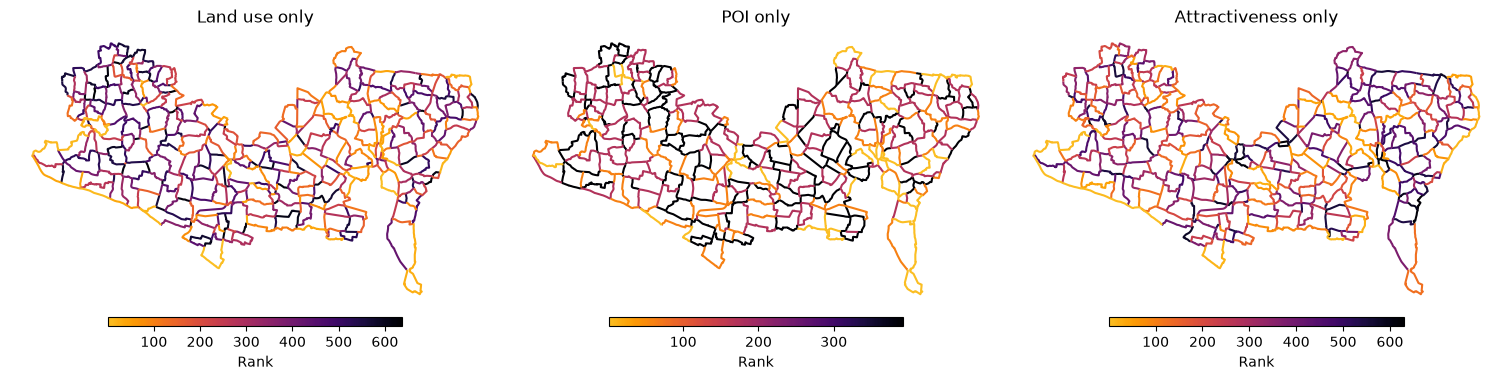

In [7]:
# Same measure, normalization and aggregation as the main specification, all weights
same = grid
for column in ("measure", "normalization", "aggregation"):
    same = same[same[column] == MAIN_SPECIFICATION[column]]

order = [weight_label(w) for w in (*COMPONENT_WEIGHTS, *REFERENCE_WEIGHTS)]
same = same.assign(weights=same[WEIGHT_COLUMNS].apply(weight_label, axis=1))
ranks_by_weight = same.pivot(index="edge_id", columns="weights", values="rank")[order]
print(ranks_by_weight.corr(method="spearman").round(2))

reference_names = {"1/0/0": "land_use_only", "0/1/0": "poi_only", "0/0/1": "attractiveness_only"}
references = ranks_by_weight[list(reference_names)].rename(columns=reference_names).reset_index()
plot_link_maps(
    edges, references,
    list(reference_names.values()),
    ["Land use only", "POI only", "Attractiveness only"],
    ["Rank", "Rank", "Rank"],
    low_is_best=[True, True, True],
);

<br><br>

## 6. Length Dependence

          length_m  score
length_m      1.00   0.21
score         0.21   1.00


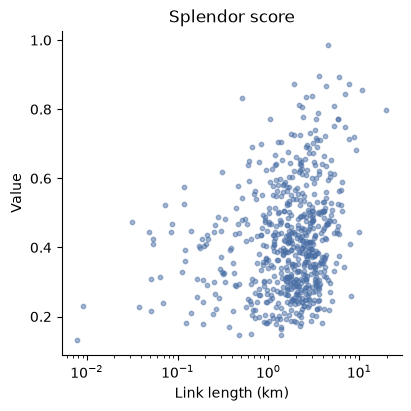

In [8]:
print(links[["length_m", "score"]].corr(method="spearman").round(2))
plot_against(
    links, "length_m", ["score"],
    titles=["Splendor score"], xlabel="Link length (km)",
    x_scale_factor=1 / 1000, xscale="log",
);